In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/USGS_RG_PFDF_Inventory_v1.csv")
df = df.replace(-9999, np.nan)   # -9999 means no data

print(df.shape)                  # rows and columns
print(df.columns.tolist())       # every column name
df.head()

Matplotlib is building the font cache; this may take a moment.


(8981, 37)
['FireName', 'FireYear', 'FireIgnitionDate', 'FireState', 'AssessmentFireID', 'AssessmentSegmentID', 'UniqueObservationID', 'SiteName', 'ObservationDate', 'ObservationLatitude', 'ObservationLongitude', 'Response', 'ObservationSource', 'StormStart', 'DaysSinceFire', 'YearAfterFire', 'GageName', 'GageID', 'GageLatitude', 'GageLongitude', 'GageDistance', 'StormAccumulation', 'StormDuration', 'PeakI15', 'PeakI30', 'PeakI60', '1YearStormI15', '1YearStormI30', '1YearStormI60', 'RainfallRatio15', 'RainfallRatio30', 'RainfallRatio60', 'HM23', 'dNBR/1000', 'KF', 'UpstreamArea', 'PreviousUSGSInventory']


,FireName,FireYear,FireIgnitionDate,FireState,AssessmentFireID,AssessmentSegmentID,UniqueObservationID,SiteName,ObservationDate,ObservationLatitude,...,1YearStormI30,1YearStormI60,RainfallRatio15,RainfallRatio30,RainfallRatio60,HM23,dNBR/1000,KF,UpstreamArea,PreviousUSGSInventory
0,Apple,2020,20200731,CA,aed2020,aed2020_7943,Apple_2020_0001,"""Dry Creek"" east of Little San Gorgonio Creek,...",20220819.0,34.052442,...,25.75,18.77,NaN,1.56,1.81,0.2670,0.2769,0.1200,1.2603,Graber (2023)
1,Apple,2020,20200731,CA,aed2020,aed2020_9918,Apple_2020_0002,Gilman Canyon (tributary to San Gorginio River...,20221129.0,34.031818,...,25.75,18.77,1.64,1.55,1.49,0.7365,0.5839,0.1279,7.5526,Graber (2023)
2,Bear,2021,20210608,UT,ber2021,ber2021_538,Bear_2021_0001,"US Hwy 6, MP 226.7, Crandall Canyon",20230903.0,39.763579,...,17.34,10.73,2.51,2.84,2.32,0.3714,0.4991,0.2720,10.8958,Graber (2024)
3,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0001,-9999,NaN,33.888020,...,15.49,11.20,0.34,0.39,0.48,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)
4,Blaisdell,2005,20050826,CA,bla,bla_122,Blaisdell_2005_0002,-9999,NaN,33.888020,...,15.49,11.20,0.44,0.49,0.36,0.0217,0.0695,0.0554,3.5557,Staley and others (2016)


In [2]:
print(df["Response"].value_counts())   # 1 = debris flow, 0 = none
print(df["Response"].mean())           # share with a debris flow

Response
0    7841
1    1140
Name: count, dtype: int64
0.12693463979512304


In [3]:
print(df["FireState"].value_counts())
print(df["FireName"].nunique(), "fires")
ca = df[df["FireState"] == "CA"]
print(len(ca), "California rows,", ca["FireName"].nunique(), "California fires")

FireState
CO    3107
CA    2867
NM    1781
AZ     813
WY     180
WA     160
MT      40
UT      33
Name: count, dtype: int64
80 fires
2867 California rows, 41 California fires


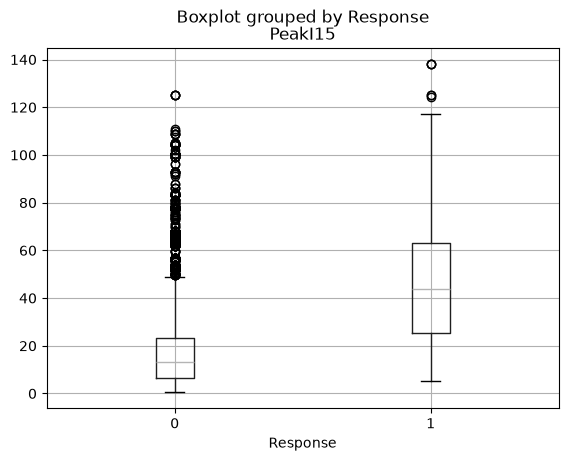

In [4]:
df.boxplot(column="PeakI15", by="Response")
plt.show()

In [5]:
print(open("../data/README.txt").read())

This README file describes data in the USGS Data Release: 

Graber, A.P., Gorr, A.N., Kean, J.W., Kostelnik, J., Rengers, F.K., Selander, B.D., and Thomas, M.A., 2026, USGS runoff-generated postfire debris-flow inventory: U.S. Geological Survey data release, https://doi.org/10.5066/P1R9VXC4.  


-----------------------------------------------------------------------------------------------------
---   1   Descriptions of field headers in "USGS_RG_PFDF_Inventory_v1.csv"
-----------------------------------------------------------------------------------------------------

Location, description, and timing information:
----------------------------------------------
FireName: Name of wildfire.
FireYear: Year of wildfire occurrence [yyyy].
FireIgnitionDate: Date of fire ignition for each fire. Most ignition dates were taken from the Monitoring Trends in Burn Severity wildfire database [yyyymmdd] (https://www.mtbs.gov/). Other ignition date sources used include: United States (U.S.) Forest S

In [6]:
print(df["PreviousUSGSInventory"].value_counts())

PreviousUSGSInventory
Graber (2023)                3005
Rengers and others (2023)    2440
Staley and others (2016)     1435
Graber (2024)                1180
New data, this version        753
Thomas and others (2023b)     154
Thomas and others (2023a)      14
Name: count, dtype: int64


In [7]:
s16 = df[df["PreviousUSGSInventory"] == "Staley and others (2016)"]
print(len(s16), "rows")
print(s16["Response"].value_counts())
print(s16["FireState"].value_counts())
print(s16[["PeakI15", "HM23", "dNBR/1000", "KF"]].isna().sum())

1435 rows
Response
0    1101
1     334
Name: count, dtype: int64
FireState
CA    824
CO    300
AZ    209
NM     58
MT     40
UT      4
Name: count, dtype: int64
PeakI15      115
HM23           0
dNBR/1000      0
KF             0
dtype: int64
